# Urban heat data explorer
Look at the training table built by `extraction/build_dataset.py`.
Change `TABLE` to `data/multi_city/all_cities_training.csv.gz` after the full run.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 60)

TABLE = "../data/smoke_test/all_cities_training.csv.gz"
df = pd.read_csv(TABLE)
print(df.shape)
df.head()

(8100, 39)


,city,climate,y,x,LST,NDVI,NDBI,MNDWI,ALBEDO,LST_std,n_obs,ELEV,LANDCOVER,GHSL_HEIGHT,GHSL_BUILT_FRAC,GHSL_POP,NDVI_nbr150,NDVI_nbr450,BUILT_nbr150,BUILT_nbr450,HEIGHT_nbr150,HEIGHT_nbr450,DIST_WATER_m,DIST_GREEN_m,SLOPE_deg,LST_z,SUHI,IS_URBAN,HOTSPOT,lon,lat,block_id,MET_T2M,MET_RH,MET_WIND,MET_SW,MET_RAIN7,MET_RAIN30,MET_T2M_SEASON_MAX
0,Pune,semi-arid,2052135.0,375225.0,42.439045,0.379748,-0.067978,-0.345535,0.132243,3.239834,26.0,572.7619,50.0,13.700758,0.304793,11.653915,0.332051,0.302818,0.307627,0.267237,13.301699,11.716604,3000.1500,216.33308,5.350215,0.188960,-2.860767,1.0,0.0,73.817655,18.556219,Pune_125_684,33.646154,21.846154,8.330769,792.519231,1.130769,4.219231,31.492359
1,Pune,semi-arid,2052135.0,375315.0,43.815850,0.384552,0.001236,-0.419995,0.129538,3.362047,26.0,568.5781,20.0,10.365025,0.168173,6.285604,0.304445,0.334759,0.203206,0.211015,10.457622,10.430727,3000.1500,150.00000,4.629806,0.680647,-1.483963,1.0,0.0,73.818507,18.556225,Pune_125_684,33.646154,21.846154,8.330769,792.519231,1.130769,4.219231,31.492359
2,Pune,semi-arid,2052135.0,375405.0,44.933273,0.199242,0.183668,-0.411093,0.121031,3.560159,26.0,565.9794,50.0,6.863740,0.095744,1.751562,0.303972,0.377920,0.108606,0.157929,7.493396,9.298696,3002.3990,60.00000,2.193651,1.079704,-0.366539,1.0,1.0,73.819360,18.556230,Pune_125_684,33.646154,21.846154,8.330769,792.519231,1.130769,4.219231,31.492359
3,Pune,semi-arid,2052135.0,375495.0,40.508780,0.499187,-0.058633,-0.456174,0.123384,3.127139,26.0,569.2996,10.0,6.556524,0.056589,1.085100,0.466459,0.399795,0.064849,0.128371,6.958612,8.353786,3007.3410,0.00000,5.444396,-0.500380,-4.791031,0.0,0.0,73.820213,18.556235,Pune_125_684,33.646154,21.846154,8.330769,792.519231,1.130769,4.219231,31.492359
4,Pune,semi-arid,2052135.0,375585.0,38.826984,0.603558,-0.213375,-0.398775,0.133774,2.982415,26.0,569.6308,10.0,7.568823,0.071129,1.775904,0.524703,0.393233,0.084213,0.137569,7.650167,8.036454,3014.9626,0.00000,5.674729,-1.100987,-6.472828,0.0,0.0,73.821065,18.556241,Pune_125_684,33.646154,21.846154,8.330769,792.519231,1.130769,4.219231,31.492359


## 1. Overview: cities, columns, missing values

In [2]:
print(df.groupby("city").size().rename("rows").to_frame().join(df.groupby("city")[["LST","NDVI","HOTSPOT"]].mean().round(2)))
miss = df.isna().mean().sort_values(ascending=False)
print("Columns with missing values:", miss[miss > 0].to_dict())
df.describe().T.round(2)

      rows    LST  NDVI  HOTSPOT
city                            
Pune  8100  41.91  0.35     0.07
Columns with missing values: {}


,count,mean,std,min,25%,50%,75%,max
y,8100.0,2048130.00,2338.27,2044125.00,2046105.00,2048130.00,2050155.00,2052135.00
x,8100.0,379230.00,2338.27,375225.00,377205.00,379230.00,381255.00,383235.00
LST,8100.0,41.91,2.81,32.13,39.98,41.85,43.66,52.92
NDVI,8100.0,0.35,0.13,-0.01,0.26,0.34,0.43,0.78
NDBI,8100.0,-0.06,0.10,-0.46,-0.12,-0.05,0.02,0.18
MNDWI,8100.0,-0.34,0.08,-0.52,-0.39,-0.33,-0.29,0.38
ALBEDO,8100.0,0.14,0.02,0.04,0.13,0.14,0.15,0.22
LST_std,8100.0,3.18,0.40,1.99,2.92,3.13,3.39,5.47
n_obs,8100.0,25.07,0.40,23.00,25.00,25.00,25.00,26.00
ELEV,8100.0,573.96,22.76,532.50,558.99,568.75,584.22,685.37


## 2. Target (LST) and hotspot labels

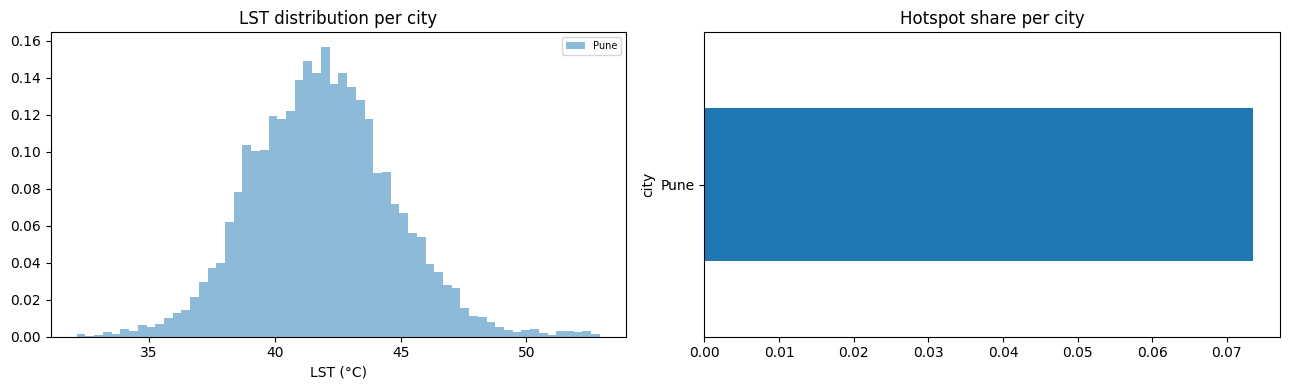

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for c, g in df.groupby("city"):
    ax[0].hist(g["LST"], bins=60, alpha=.5, label=c, density=True)
ax[0].set_xlabel("LST (°C)"); ax[0].set_title("LST distribution per city")
if df["city"].nunique() <= 15: ax[0].legend(fontsize=7)
df.groupby("city")["HOTSPOT"].mean().sort_values().plot.barh(ax=ax[1])
ax[1].set_title("Hotspot share per city"); plt.tight_layout()

## 3. Maps (lon/lat scatter) for one city

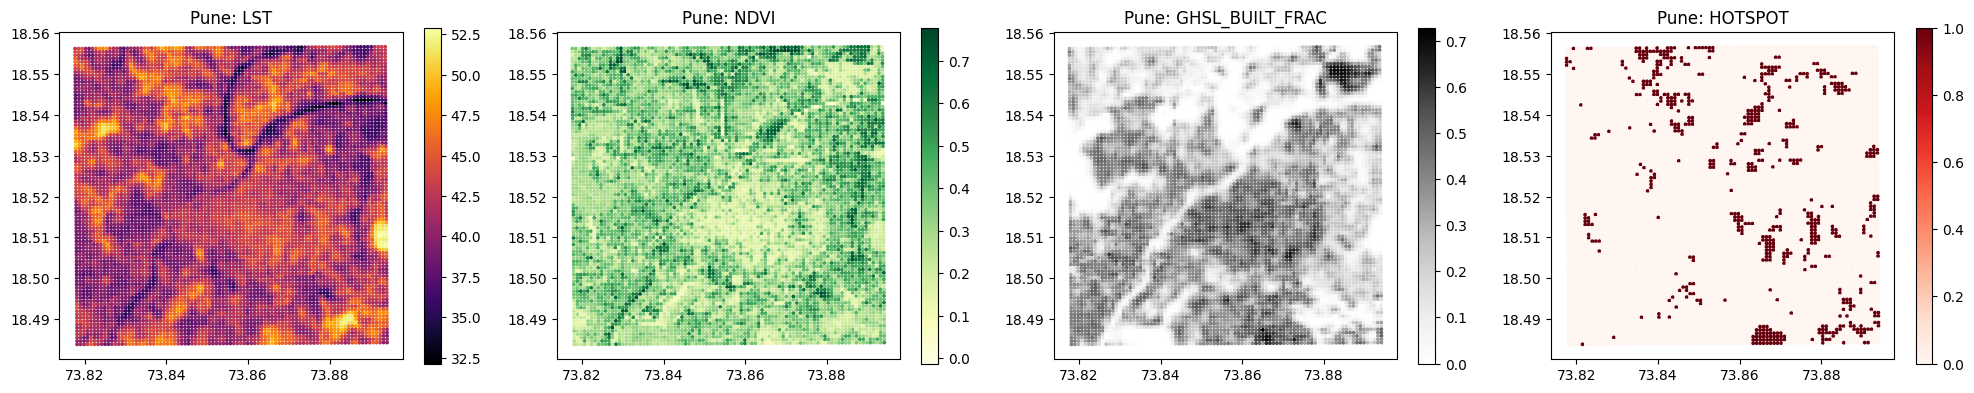

In [4]:
CITY = df["city"].iloc[0]          # change to any city name
g = df[df.city == CITY]
fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
for a, (col, cmap) in zip(ax, [("LST","inferno"), ("NDVI","YlGn"), ("GHSL_BUILT_FRAC","Greys"), ("HOTSPOT","Reds")]):
    s = a.scatter(g.lon, g.lat, c=g[col], s=3, cmap=cmap); a.set_title(f"{CITY}: {col}")
    a.set_aspect("equal"); plt.colorbar(s, ax=a, shrink=.8)
plt.tight_layout()

## 4. What relates to LST? (correlation with the target)

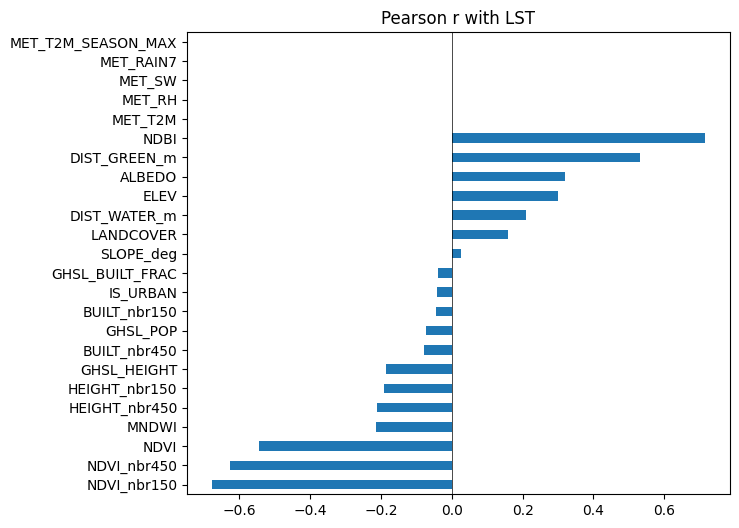

In [5]:
feat = [c for c in df.select_dtypes("number").columns
        if c not in ["LST","LST_z","SUHI","HOTSPOT","x","y","lon","lat","n_obs","LST_std"] and df[c].std() > 0]
corr = df[feat + ["LST"]].corr()["LST"].drop("LST").sort_values()
corr.plot.barh(figsize=(7, max(4, .25*len(corr)))); plt.title("Pearson r with LST"); plt.axvline(0, c="k", lw=.5)

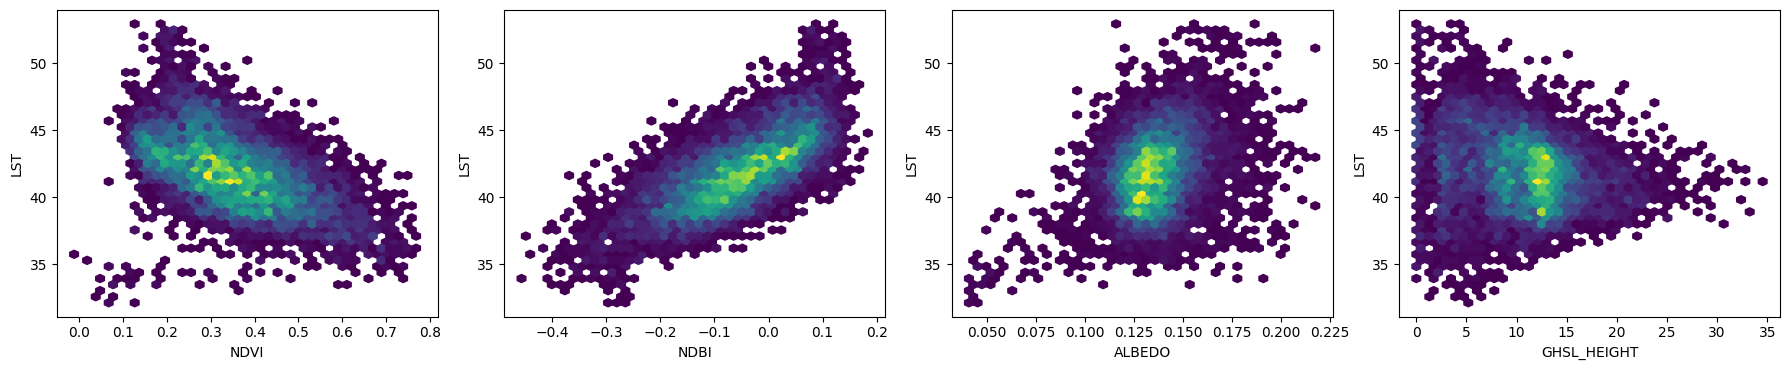

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
samp = df.sample(min(len(df), 20000), random_state=0)
for a, col in zip(ax, ["NDVI","NDBI","ALBEDO","GHSL_HEIGHT"]):
    a.hexbin(samp[col], samp["LST"], gridsize=40, cmap="viridis", mincnt=1); a.set_xlabel(col); a.set_ylabel("LST")
plt.tight_layout()

## 5. Land cover and hotspots
ESA WorldCover: 10 tree, 20 shrub, 30 grass, 40 crop, 50 built-up, 60 bare, 80 water.

In [7]:
lc = df.groupby("LANDCOVER").agg(n=("LST","size"), LST=("LST","mean"), hotspot=("HOTSPOT","mean")).round(2)
lc

,n,LST,hotspot
LANDCOVER,,,
10.0,2939,40.53,0.01
20.0,560,44.45,0.07
30.0,356,45.97,0.09
40.0,156,43.85,0.07
50.0,3962,42.27,0.12
60.0,28,43.56,0.11
80.0,99,35.97,0.00


## 6. Feature correlation (check redundancy)

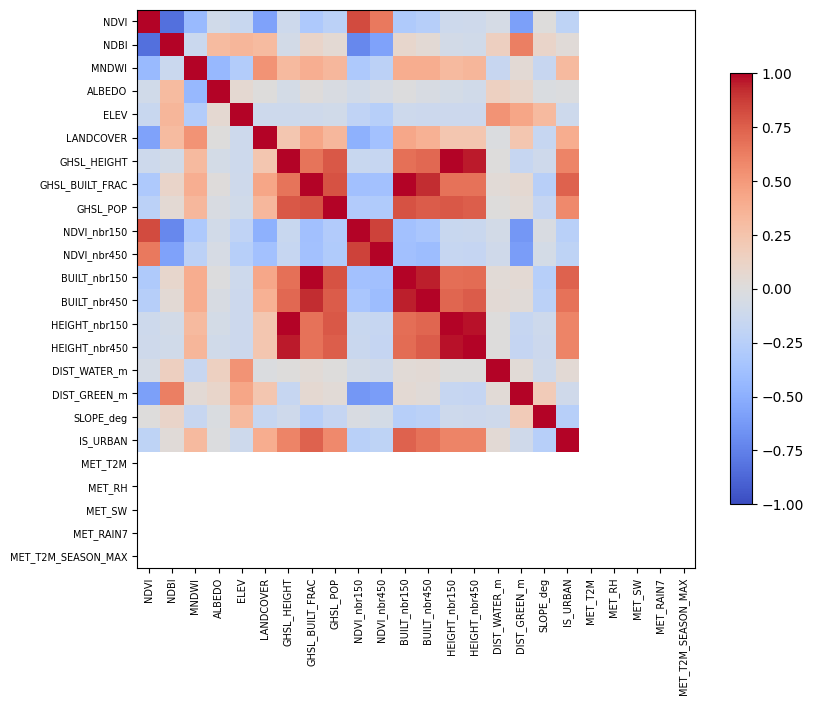

In [8]:
c = df[feat].corr()
fig, ax = plt.subplots(figsize=(9, 8)); im = ax.imshow(c, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(feat))); ax.set_xticklabels(feat, rotation=90, fontsize=7)
ax.set_yticks(range(len(feat))); ax.set_yticklabels(feat, fontsize=7); plt.colorbar(im, shrink=.7)

## 7. Quick baseline (sanity check, not the final model)
Random forest with spatial-block split (whole 3 km blocks held out).

R2 0.776 | MAE 1.07 °C


<Axes: title={'center': 'RF feature importance'}>

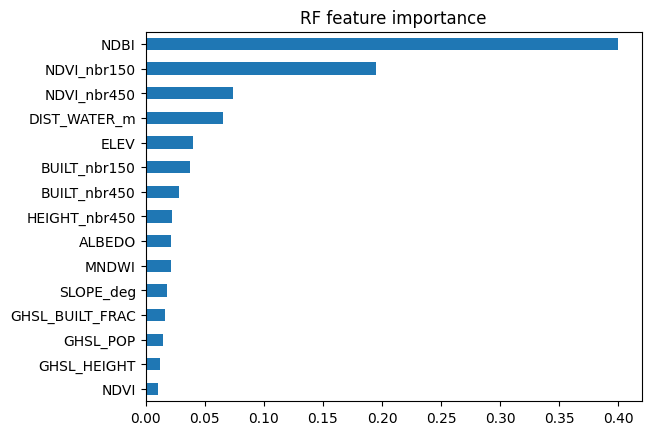

In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import r2_score, mean_absolute_error

X, y, grp = df[feat].fillna(df[feat].median()), df["LST"], df["block_id"]
tr, te = next(GroupShuffleSplit(test_size=.25, random_state=0).split(X, y, grp))
rf = RandomForestRegressor(200, n_jobs=-1, random_state=0).fit(X.iloc[tr], y.iloc[tr])
p = rf.predict(X.iloc[te])
print(f"R2 {r2_score(y.iloc[te], p):.3f} | MAE {mean_absolute_error(y.iloc[te], p):.2f} °C")
pd.Series(rf.feature_importances_, feat).sort_values().tail(15).plot.barh(title="RF feature importance")